# 07 · Monitoring et calendrier : faire vivre la mesure, et décider avec

Rien d'observable ne dit si un contrefactuel est juste. Le monitoring surveille donc quatre substituts (chacun
lié à un mode de défaillance que le notebook 04 sait reproduire) et un garde-fou métier : la réconciliation de
la marge incrémentale estimée avec la marge réalisée, dont la **dérive** est l'alarme. Puis le calendrier :
réallouer des jours de campagne à budget constant, sur la borne basse des uplifts, sans promouvoir deux
familles substituables la même semaine. Les chiffres viennent de `nr monitor` et `nr calendar`.

**Attention.** Favorita n'a pas de marge. La réconciliation est démontrée sur un grand livre **simulé** à partir
des estimations (bruit + dérive injectée à une date connue) ; le code est celui qu'un vrai grand livre alimenterait.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from novaretail import viz
from novaretail.data import RESULTS
from novaretail.monitoring import ALERTS, fit_signals

viz.setup()
export = viz.exporter("../figures")
rep = json.loads((RESULTS / "monitor.json").read_text())
cal = json.loads((RESULTS / "calendar.json").read_text())
est = pd.read_parquet(RESULTS / "estimates.parquet")
est = est[est["status"] != "pool_too_small"]
print(rep)

{'campaigns': 284, 'blocked_by_fit': 71, 'fpr_never_treated': 0.1724137931034483, 'fpr_alert_share': 0.6551724137931034, 'isolation_reviews': 114, 'donor_sign_changes': 223, 'reconciliation_clean_alarms': 1, 'reconciliation_drift_alarms': 12, 'reconciliation_drift_first_alarm': '2014-11', 'reconciliation_alarms_after_injection': 11, 'reconciliation_first_alarm_after_injection': '2016-07', 'drift_injected_from': '2016-04'}


## 1. Signal 1 : l'ajustement de pré-période de chaque campagne

**Intuition.** Trois contrôles par campagne, dans le temps : un modèle qui cesse de prévoir la pré-période
(R² qui s'effondre, couverture un pas en avant hors de [0,90 ; 0,98], résidus autocorrélés) bloque le rapport
de cette campagne. La figure les suit campagne par campagne.

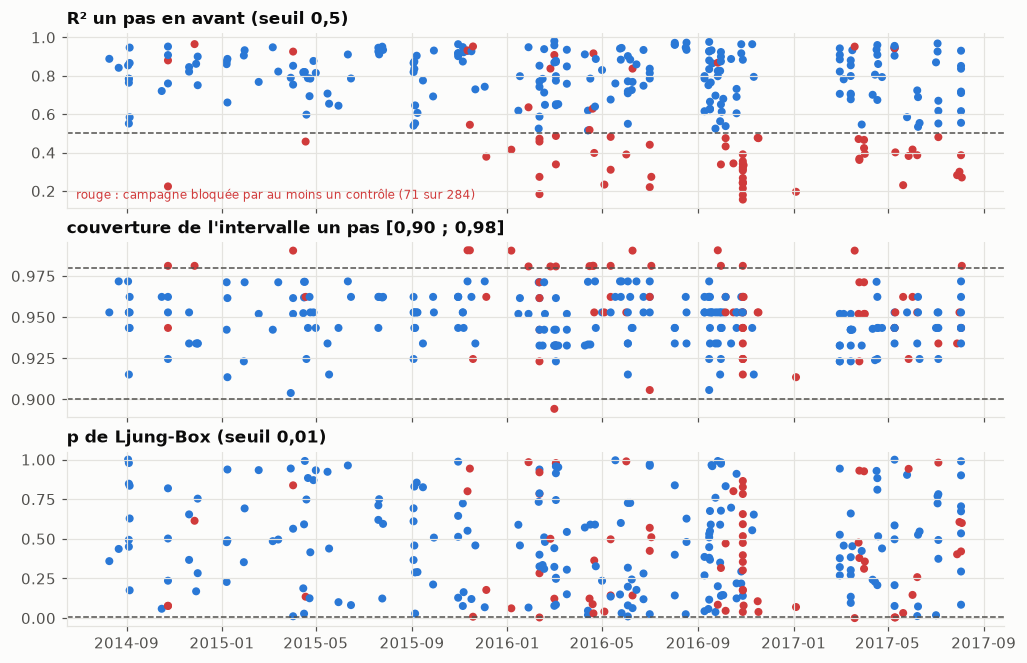

In [2]:
fit = fit_signals(est).sort_values("start")
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
specs = ((axes[0], "r2_one_step", (0.5, None), "R² un pas en avant (seuil 0,5)"),
         (axes[1], "coverage_one_step", (0.90, 0.98), "couverture de l'intervalle un pas [0,90 ; 0,98]"),
         (axes[2], "ljung_box_p", (0.01, None), "p de Ljung-Box (seuil 0,01)"))
for ax, col, (lo, hi), title in specs:
    colors = [viz.CRITICAL if b else viz.BLUE for b in fit["blocked"]]
    ax.scatter(fit["start"], fit[col], c=colors, s=18)
    ax.axhline(lo, color=viz.TEXT_2, linestyle="--", linewidth=1)
    if hi:
        ax.axhline(hi, color=viz.TEXT_2, linestyle="--", linewidth=1)
    ax.set_title(title)
axes[0].text(0.01, 0.05, f"rouge : campagne bloquée par au moins un contrôle ({rep['blocked_by_fit']} sur "
             f"{rep['campaigns']})", transform=axes[0].transAxes, fontsize=8, color=viz.CRITICAL)
export(fig, "nb07_fit_signals")
plt.show()

## 2. Signal 2 : le placebo roulant sur des séries jamais traitées

**Exemple.** Le taux de faux positifs du design, mesuré en continu sur des fenêtres où rien ne s'est passé
(les fenêtres à effet nul du backtesting, ici), lissé sur les derniers runs. Au-dessus de 10 % (le nominal est
5 %, la veille mesurait 11 % sur des pré-périodes courtes), le design est en alerte : ses intervalles ne
couvrent plus.

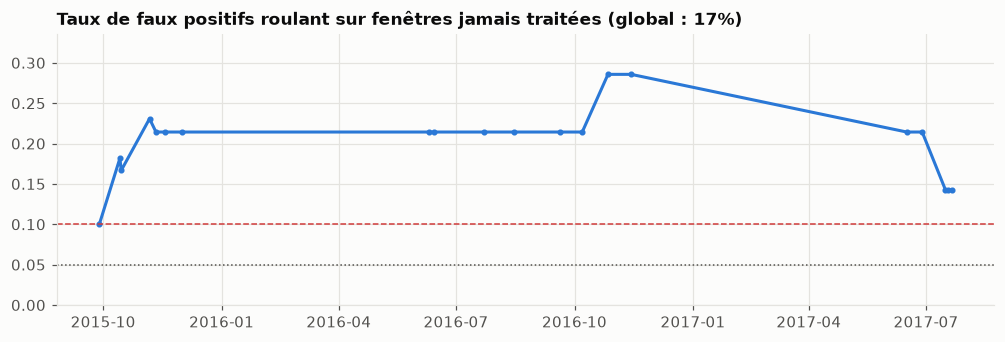

In [3]:
fpr = pd.read_parquet(RESULTS / "rolling_fpr.parquet")
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(fpr["start"], fpr["fpr_rolling"], color=viz.BLUE, marker="o", markersize=3)
ax.axhline(ALERTS["fpr_max"], color=viz.CRITICAL, linestyle="--", linewidth=1)
ax.axhline(0.05, color=viz.TEXT_2, linestyle=":", linewidth=1)
ax.set_ylim(0, max(0.3, float(fpr["fpr_rolling"].max() or 0) + 0.05))
ax.set_title(f"Taux de faux positifs roulant sur fenêtres jamais traitées (global : {rep['fpr_never_treated']:.0%})")
export(fig, "nb07_rolling_fpr")
plt.show()

## 3. Signaux 3 et 4 : interférence et stabilité de la relation donneur-cible

**Attention.** Le nombre de donneurs retirés par l'isolation est un signal d'interférence ; au-delà d'un tour,
revue humaine. Et pour une même cible, le coefficient d'un même donneur d'une campagne à la suivante doit
rester du même signe : un changement de signe bloque ce donneur pour cette cible. Mais lisez le signal 3 avec
le signal 2 : si le design se déclenche 10 % du temps sur du vide, il « isole » un donneur sur dix par bruit.

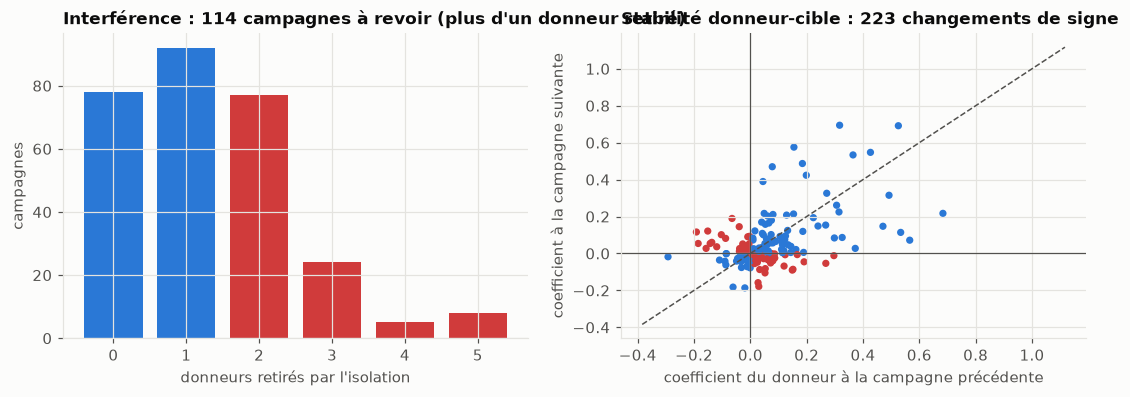

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axes[0]
rm = est["removed_donors"].fillna(0).astype(int).value_counts().sort_index()
ax.bar(rm.index, rm.values, color=[viz.BLUE if k <= ALERTS["isolation_rounds_max"] else viz.CRITICAL for k in rm.index])
ax.set_xlabel("donneurs retirés par l'isolation")
ax.set_ylabel("campagnes")
ax.set_title(f"Interférence : {rep['isolation_reviews']} campagnes à revoir (plus d'un donneur retiré)")
ax = axes[1]
p = RESULTS / "relationship_drift.parquet"
if p.exists():
    dr = pd.read_parquet(p).dropna(subset=["beta_prev"])
    ax.scatter(dr["beta_prev"], dr["beta"], c=[viz.CRITICAL if s else viz.BLUE for s in dr["sign_change"]], s=14)
    lim = [min(dr["beta_prev"].min(), dr["beta"].min()), max(dr["beta_prev"].max(), dr["beta"].max())]
    ax.plot(lim, lim, color=viz.TEXT_2, linestyle="--", linewidth=1)
    ax.axhline(0, color=viz.TEXT_2, linewidth=0.8)
    ax.axvline(0, color=viz.TEXT_2, linewidth=0.8)
    ax.set_xlabel("coefficient du donneur à la campagne précédente")
    ax.set_ylabel("coefficient à la campagne suivante")
    ax.set_title(f"Stabilité donneur-cible : {rep['donor_sign_changes']} changements de signe")
export(fig, "nb07_interference_drift")
plt.show()

## 4. Le garde-fou métier : réconcilier la marge

**Intuition.** L'uplift estimé est un résidu de prévision ; la marge réalisée est un fait comptable. Chaque
mois, la somme des marges contrefactuelles et incrémentales estimées est comparée à la marge réalisée des
couples magasin-famille promus. L'écart est bruité ; sa **dérive** (même signe trois mois de suite, au-delà de
2 %) est l'alarme. C'est le seul signal qui voit une relation donneur-cible qui casse à la date de campagne.
Deux grands livres simulés : un propre, un avec une dérive de 2 % par mois injectée à une date connue.

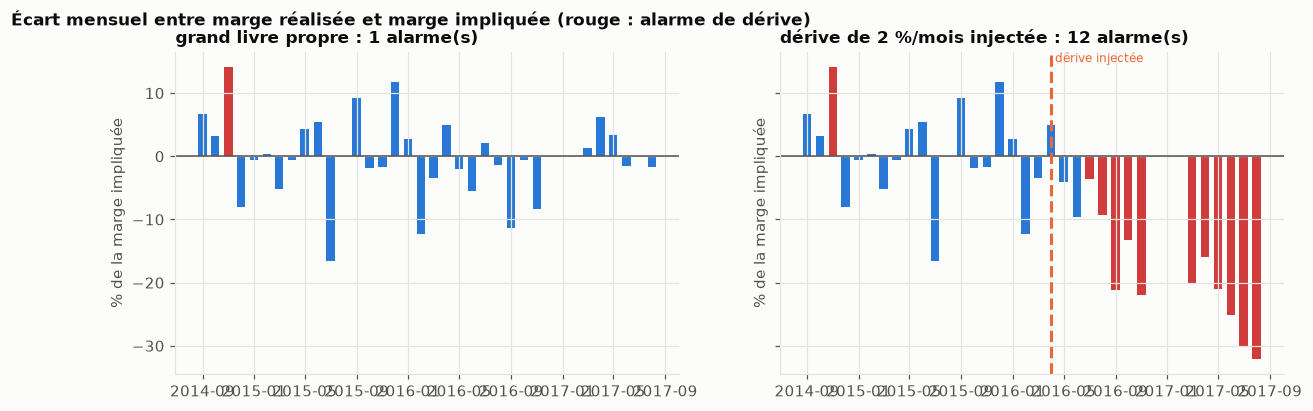

dérive injectée à partir de 2016-04, première alarme : 2014-11


In [5]:
clean = pd.read_parquet(RESULTS / "reconciliation_clean.parquet")
drift = pd.read_parquet(RESULTS / "reconciliation_drift.parquet")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
fig.suptitle("Écart mensuel entre marge réalisée et marge impliquée (rouge : alarme de dérive)", x=0.01, ha="left",
             fontsize=11, fontweight="bold")
for ax, rec, title in ((axes[0], clean, "grand livre propre"), (axes[1], drift, "dérive de 2 %/mois injectée")):
    x = rec.index.to_timestamp()
    ax.bar(x, rec["gap_share"] * 100, width=20, color=[viz.CRITICAL if a else viz.BLUE for a in rec["drift_alarm"]])
    ax.axhline(0, color=viz.TEXT_2, linewidth=1)
    ax.set_title(f"{title} : {int(rec['drift_alarm'].sum())} alarme(s)")
    ax.set_ylabel("% de la marge impliquée")
if rep.get("drift_injected_from"):
    t0 = pd.Period(rep["drift_injected_from"], "M").to_timestamp()
    axes[1].axvline(t0, color=viz.ORANGE, linestyle="--")
    axes[1].text(t0, axes[1].get_ylim()[1], " dérive injectée", color=viz.ORANGE, fontsize=8, va="top")
export(fig, "nb07_reconciliation")
plt.show()
print(f"dérive injectée à partir de {rep['drift_injected_from']}, première alarme : "
      f"{rep['reconciliation_drift_first_alarm']}")

## 5. Le calendrier : réallouer à budget constant, sur la borne basse

**Exemple.** Par magasin, les jours de campagne historiques sont redistribués vers les familles dont la valeur
par jour (uplift net, borne basse de l'intervalle, par jour de campagne mesuré) est la plus élevée, avec un
plafond de deux fois l'historique par famille (la réponse est mesurée à l'intensité historique, pas au-delà)
et sans toucher aux familles non mesurées. Puis les semaines sont attribuées sans que deux familles liées par
une arête de substitution se chevauchent dans un magasin.

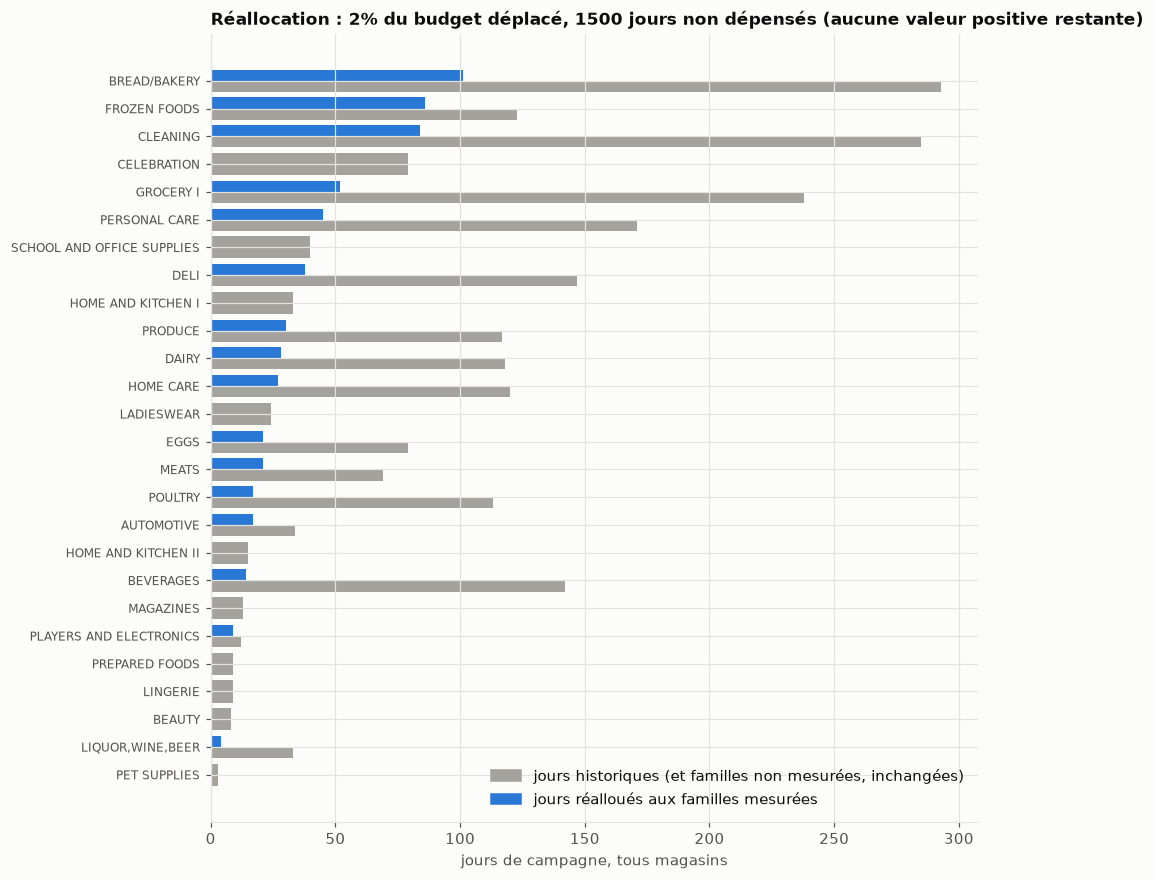

{'stores': 53, 'budget_days': 2327, 'days_moved': 48, 'share_moved': 0.020627417275461968, 'unspent_days': 1500, 'families_unmeasured': 10, 'expected_gain_units': 1090901.7198814186}


In [6]:
plan = pd.read_parquet(RESULTS / "calendar_plan.parquet")
agg = plan.groupby("family").agg(hist=("hist_days", "sum"), new=("new_days", "sum"), measured=("measured", "any"))
agg = agg.sort_values("new")
fig, ax = plt.subplots(figsize=(9, 0.3 * len(agg) + 1.5))
ypos = np.arange(len(agg))
from matplotlib.patches import Patch

ax.barh(ypos - 0.2, agg["hist"], height=0.4, color=viz.MUTED)
ax.barh(ypos + 0.2, agg["new"], height=0.4, color=[viz.BLUE if m else viz.MUTED for m in agg["measured"]])
ax.legend(handles=[Patch(color=viz.MUTED, label="jours historiques (et familles non mesurées, inchangées)"),
                   Patch(color=viz.BLUE, label="jours réalloués aux familles mesurées")], loc="lower right")
ax.set_yticks(ypos, agg.index, fontsize=8)
ax.set_xlabel("jours de campagne, tous magasins")
ax.set_title(f"Réallocation : {cal['share_moved']:.0%} du budget déplacé, {cal['unspent_days']} jours non dépensés "
             f"(aucune valeur positive restante)")
export(fig, "nb07_calendar")
plt.show()
print(cal)

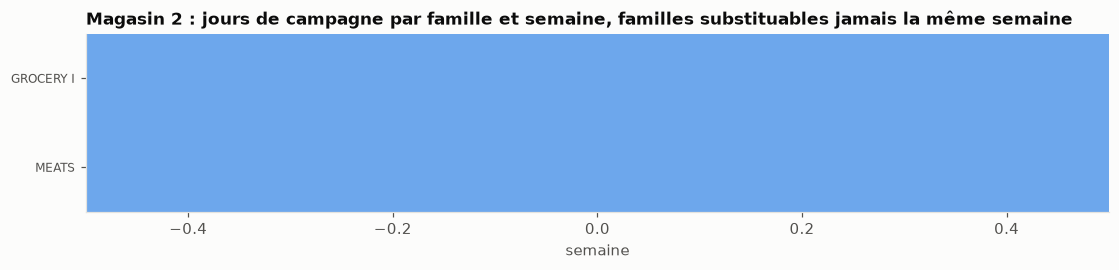

In [7]:
sched = pd.read_parquet(RESULTS / "calendar_schedule.parquet")
store = int(sched["store_nbr"].iloc[0])
grid = sched[sched["store_nbr"] == store].pivot_table(index="family", columns="week", values="days", fill_value=0)
fig, ax = plt.subplots(figsize=(12, 0.3 * len(grid) + 1.5))
ax.imshow(grid.values, aspect="auto", cmap=viz.base.SEQUENTIAL, vmin=0, vmax=7)
ax.set_yticks(range(len(grid)), grid.index, fontsize=8)
ax.set_xlabel("semaine")
ax.grid(False)
ax.set_title(f"Magasin {store} : jours de campagne par famille et semaine, familles substituables jamais la même semaine")
export(fig, "nb07_schedule")
plt.show()

## À retenir

- Quatre signaux surveillent des substituts du contrefactuel : ajustement, faux positifs sur du vide,
  interférence, stabilité donneur-cible. Aucun ne voit une relation qui casse à la date de campagne.
- Le garde-fou métier le voit, avec retard : la dérive de l'écart de réconciliation.
- La décision prend la **borne basse** tant que la famille n'est pas réconciliée ; ce que le calendrier déplace
  est petit, et c'est normal : la plupart des familles n'ont pas de campagne mesurable.